In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import TABLE_DIR, FIG_DIR, save_fig, save_table

sns.set_theme(style="whitegrid")

bin_df = pd.read_csv(TABLE_DIR / "04_baseline_binary.csv")
mc_df = pd.read_csv(TABLE_DIR / "04_baseline_multiclass.csv")
print(bin_df.shape, mc_df.shape)

Mounted at /content/drive
(6, 10) (6, 19)


[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/05_binary_precision_recall_f1.png


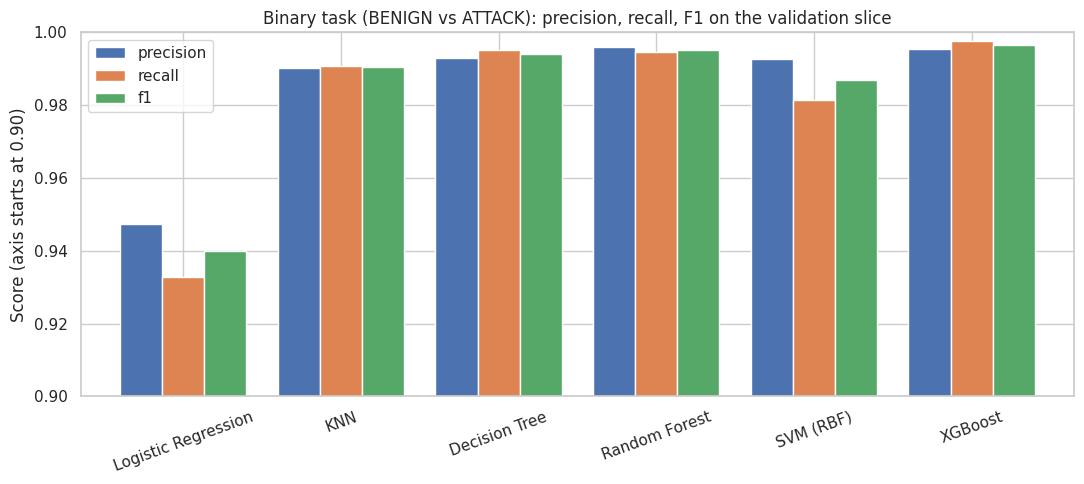

In [2]:
ax = bin_df.set_index("model")[["precision", "recall", "f1"]].plot.bar(figsize=(11, 5), width=0.8)
ax.set_ylim(0.90, 1.0)
ax.set_title("Binary task (BENIGN vs ATTACK): precision, recall, F1 on the validation slice")
ax.set_ylabel("Score (axis starts at 0.90)")
ax.set_xlabel("")
plt.xticks(rotation=20)
save_fig("05_binary_precision_recall_f1")
plt.show()

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/05_multiclass_accuracy_vs_macro_f1.png


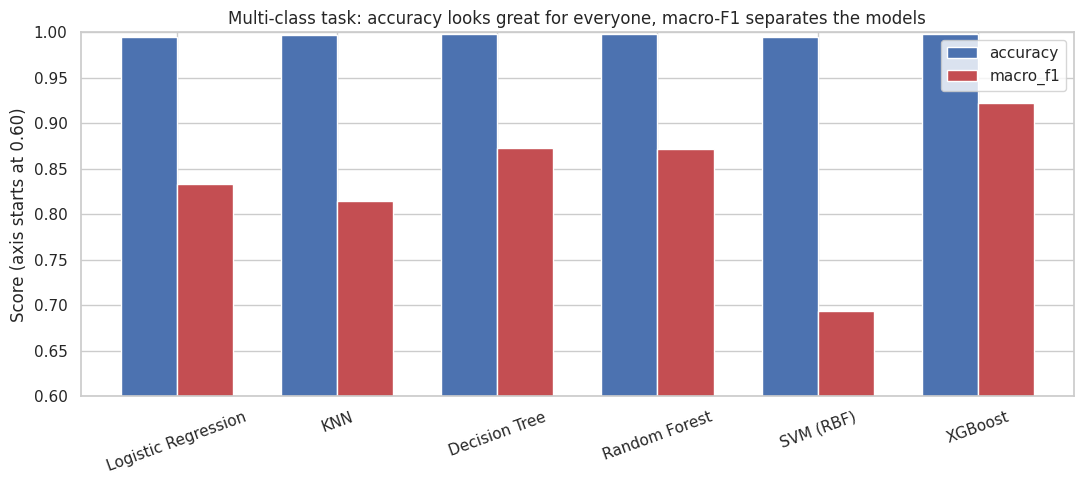

In [3]:
ax = mc_df.set_index("model")[["accuracy", "macro_f1"]].plot.bar(figsize=(11, 5), width=0.7,
                                                                  color=["#4C72B0", "#C44E52"])
ax.set_ylim(0.6, 1.0)
ax.set_title("Multi-class task: accuracy looks great for everyone, macro-F1 separates the models")
ax.set_ylabel("Score (axis starts at 0.60)")
ax.set_xlabel("")
plt.xticks(rotation=20)
save_fig("05_multiclass_accuracy_vs_macro_f1")
plt.show()

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/05_per_class_f1_heatmap.png


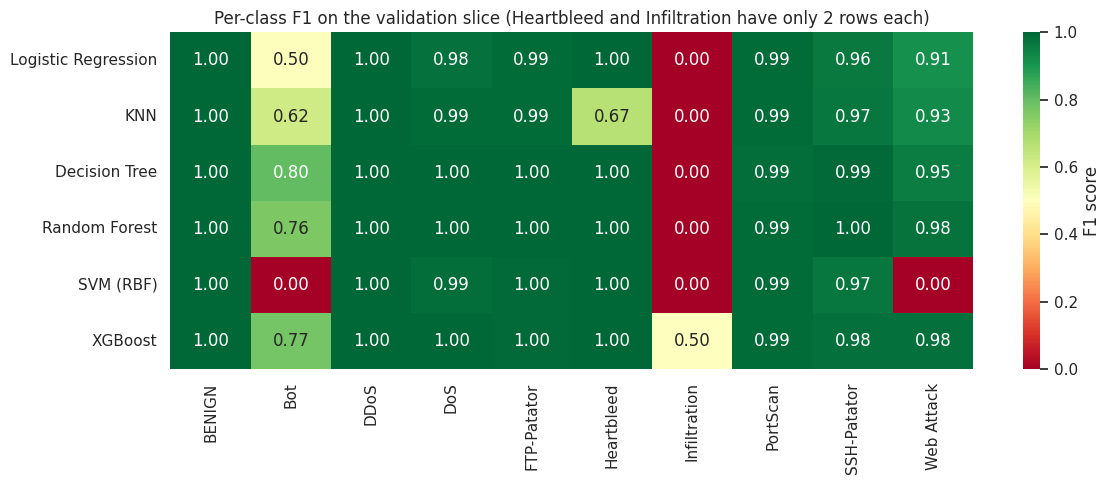

[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/05_per_class_f1.csv


In [4]:
f1_cols = [c for c in mc_df.columns if c.startswith("f1_")]
heat = mc_df.set_index("model")[f1_cols]
heat.columns = [c.replace("f1_", "") for c in heat.columns]

plt.figure(figsize=(12, 5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "F1 score"})
plt.title("Per-class F1 on the validation slice (Heartbleed and Infiltration have only 2 rows each)")
plt.ylabel("")
save_fig("05_per_class_f1_heatmap")
plt.show()
save_table(heat.round(4), "05_per_class_f1")

[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/05_training_prediction_time.png


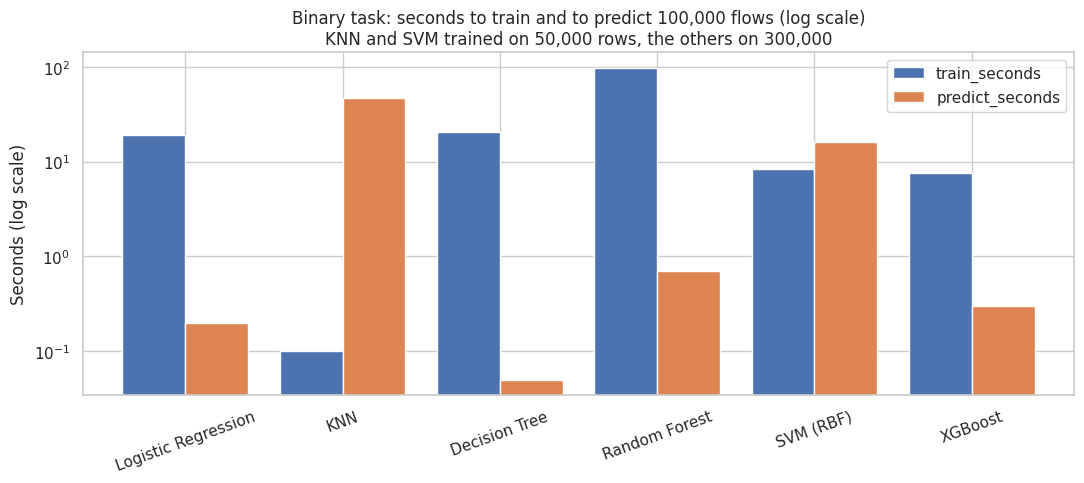

In [5]:
t = bin_df.set_index("model")[["train_seconds", "predict_seconds"]].clip(lower=0.05)
ax = t.plot.bar(figsize=(11, 5), width=0.8, logy=True)
ax.set_title("Binary task: seconds to train and to predict 100,000 flows (log scale)\n"
             "KNN and SVM trained on 50,000 rows, the others on 300,000")
ax.set_ylabel("Seconds (log scale)")
ax.set_xlabel("")
plt.xticks(rotation=20)
save_fig("05_training_prediction_time")
plt.show()

In [6]:
rank = pd.DataFrame({
    "binary_f1": bin_df.set_index("model")["f1"],
    "binary_pr_auc": bin_df.set_index("model")["pr_auc"],
    "multi_macro_f1": mc_df.set_index("model")["macro_f1"],
    "multi_accuracy": mc_df.set_index("model")["accuracy"],
    "train_s_binary": bin_df.set_index("model")["train_seconds"],
    "predict_s_binary": bin_df.set_index("model")["predict_seconds"],
})
rank["rank_binary"] = rank["binary_f1"].rank(ascending=False, method="min")
rank["rank_multi"] = rank["multi_macro_f1"].rank(ascending=False, method="min")
rank["avg_rank"] = rank[["rank_binary", "rank_multi"]].mean(axis=1)
rank = rank.sort_values("avg_rank")
print(rank.round(4).to_string())
save_table(rank.round(4), "05_model_ranking")

print("\nFigures saved by this notebook:")
for f in sorted(FIG_DIR.glob("05_*")):
    print(" -", f.name)

                     binary_f1  binary_pr_auc  multi_macro_f1  multi_accuracy  train_s_binary  predict_s_binary  rank_binary  rank_multi  avg_rank
model                                                                                                                                             
XGBoost                 0.9966         0.9998          0.9221          0.9986             7.6               0.3          1.0         1.0       1.0
Random Forest           0.9952         0.9970          0.8719          0.9983            97.8               0.7          2.0         3.0       2.5
Decision Tree           0.9939         0.9890          0.8729          0.9981            20.4               0.0          3.0         2.0       2.5
KNN                     0.9904         0.9926          0.8143          0.9966             0.1              47.0          4.0         5.0       4.5
Logistic Regression     0.9400         0.9729          0.8335          0.9952            19.2               0.2       